# Does a neuron reading tell a fine-tune on facts Qwen knows from one on facts it lacks?

*E103 with Amendments 1 and 2, 2026-11-06. **Provisional**: fast lane, no independent check. Full record and scoring:
`reports/analyses/2026-11-06_analysis_e103-known-answer-pair.md`.*

## The answer

Two known-facts seeds now sit level with the fictional-facts update on all four summary neuron readings at the
template's size. Which neurons carry each update does separate the two kinds of training. Each kind's two seeds share
about nine tenths of their carrying neurons. A known-facts and a fictional run share about half, or under two thirds on
the fictional rows: beyond seed noise on both row sets. The two kinds also train on different rows, and that control is
not run, so this is a candidate signal, not a finding. Amendment 1's apparent loss of real facts was a scoring effect.

*The first run found the same level readings, but its gain control passed mostly because the model learned to give a
bare phrase and stop. Its sections come first below. Amendment 1 removed that format lesson; Amendment 2 added a second
seed of Amendment 1's known-facts run and read why its end state seemed to lose facts.*


## What we were trying to test

`GOALS.md` asks whether post-training strengthens what a model already does or teaches it something new, and whether a
method can tell which. E102 read Qwen3-1.7B's MLP neurons on a template fine-tune, labelled reuse, and a fine-tune on
fictional authors' facts, labelled new. Those two differed in task, rows, recipe and size as well as label, so nothing
could be put down to the label. Here we build a pair meant to differ in the label alone.

**Two fine-tunes, one recipe.** Both train on rows of TOFU, a benchmark of question-answer pairs. Each row is trained in
five wordings: TOFU's own question and answer, plus four rewordings. The recipe is E84's: peak rate 2e-5 after a
250-step warm-up, batch 16, fp32.

- The *known-facts fine-tune*, new here, trains on TOFU's 217 real-person and world-fact rows, such as "Who wrote the
  play 'Romeo and Juliet'?" with "William Shakespeare". The unchanged model, W0, already picks 0.79 of these right.
- The *fictional fine-tune*, read from E84 and E91, trains on 787 rows about invented authors that W0 cannot know.

**Two points on each run.** The *matched* state is the step whose total weight change, the Frobenius norm of the change
over all linear layers, is nearest the template fine-tune's 0.49. That is step 33 here and step 29 for the fictional
run, both inside warm-up at the same rate. The *end* state is the last step. The end states also differ in size, 8.3
against 18.1, so they are reported, not scored.

**What is read.**

- *Gain*: for each real row, the change from W0 in the mean log P per token of the trained answer, end-of-turn token
  included, after the question with " Answer in one sentence."; averaged over rows. 0 means nothing moved.
- *Real-fact share*: four-way multiple choice on the 217 real facts. Chance is 0.25; W0 reads 0.79.
- *Carrying set*: the 1,024 of Qwen's 172,032 MLP neurons whose change in firing contributes most to a state's gain on
  a set of rows, to first order. Read on the real rows and on 128 rows of fictional facts.
- *Prompt overlap*: the share of a carrying set inside the 1,024 neurons that a system prompt moves most. E102's set.
- *Engaged share*: how strongly W0 already fires those neurons at the answers, as a quantile of their firing on web
  text. 0.5 is typical web text.
- *References*: a random Gaussian weight change as the floor, and 100 random neuron sets per state.

A reading separates the pair only if the known-facts state differs from the two fictional seeds' mean by more than a
band, and also clears the floor. The band is the larger of the seeds' spread and twice the random sets' spread.


## What we expected, and why

- **The gain would clear half the template's gain, 0.33, and land above 1.** Below that, the update had nothing for the
  neurons to carry and the run would stop. The filed note already expected answer format to earn most of it, since a
  bare short answer after a request for a sentence is unlikely under W0.
- **The known-facts states would keep the real facts, and the fictional end state would lose them**, as E81's fictional
  fine-tune fell from 0.79 to 0.42.
- **Engaged share and prompt overlap would read level at matched size.** E102 had found engaged share flat at 0.50 for
  every set, and prompt overlap only one band apart between opposite labels. A difference here, with only the label
  changed, would be the first sign these instruments read the label.


In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

from commute.jobs import load_experiment

PLOT = load_experiment("known_answer_pair", "plot")
PLOT.main()  # redraws the ten figures from results/*.json; the tokenizer is loaded for answer lengths, not the model
FIG = Path("../experiments/known_answer_pair/figures")
RES = Path("../experiments/known_answer_pair/results")
train = json.loads((RES / "train.json").read_text())
print(f"matched step {train['matched']['step']}, weight change {train['matched']['norm']:.4f} against the template's 0.4865; "
      f"gain there {train['matched']['gain']:.2f} nats a token against a bar of {train['matched']['bar']}")


/mnt/nw/home/e.agnew/commute-data/venv-py313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


wrote ['amend1_overlap.png', 'amend1_pair_rules.png', 'amend1_positions.png', 'amend1_recall.png', 'amend1_shared.png', 'gain_curve.png', 'pair_rules.png', 'prompt_overlap.png', 'recall.png', 'w0_deficit.png']
matched step 33, weight change 0.4887 against the template's 0.4865; gain there 11.35 nats a token against a bar of 0.333


## What we observed

### Is the control's gain about the facts?

The gain at the matched step read 11.35 nats a token. That is seventeen times the template's gain and above the
fictional state's 6.72, on facts W0 already knows. A number like that has to be explained before anything is read off
it. First, where does W0's low score sit inside each answer?


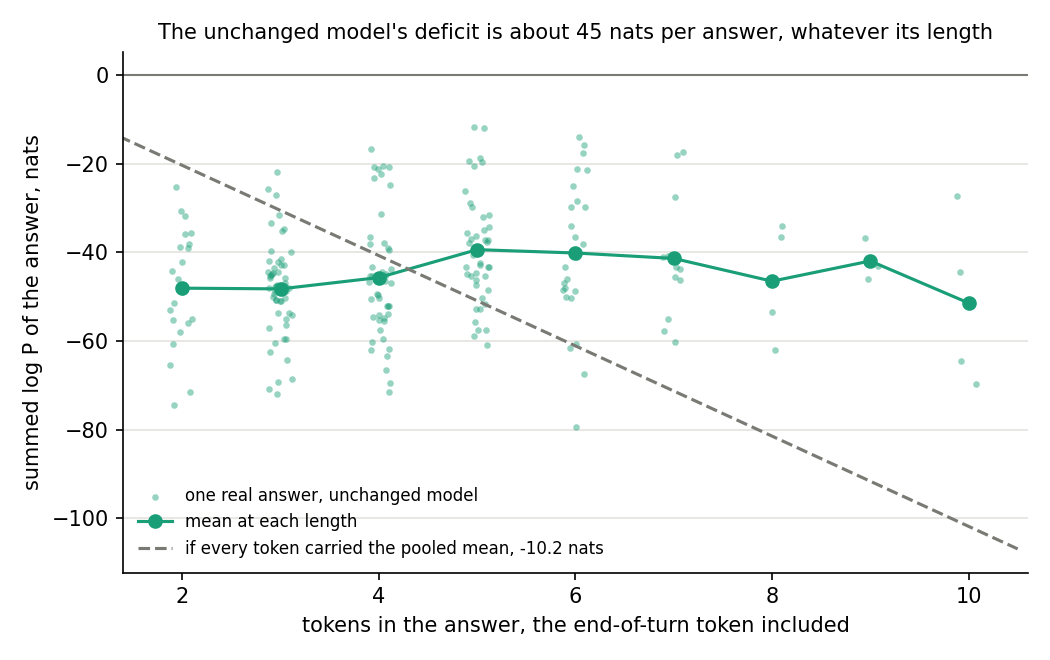

In [2]:
display(Image(FIG / "w0_deficit.png", width=750))


**Reading it.** On one token, not across the answer. The figure plots, for each real answer, W0's summed log P against
the answer's length in tokens. If every token were equally unlikely, the points would follow the grey dashed line down.
Instead the sum stays near −45 nats from two tokens to ten. A fixed deficit per answer points to one token. The likely
one is the end of turn: asked for one sentence, Qwen does not stop after a bare "William Shakespeare". Amendment 1 later
read each position and confirmed it: the end token and the answer's first token carry the gain.


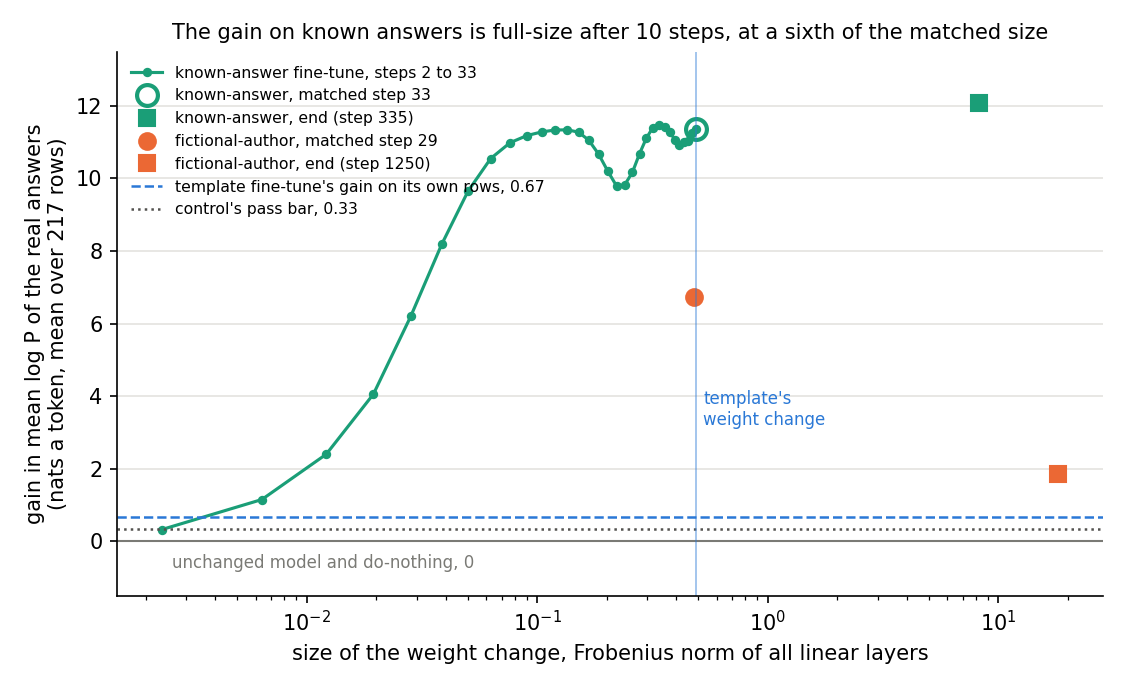

In [3]:
display(Image(FIG / "gain_curve.png", width=800))


**Reading it.** The gain is mostly a format habit, learned in ten steps. The green curve is the gain at each early step,
plotted against the size of the weight change. By step 10, at a sixth of the matched size, it has reached 97% of its
matched value. 217 separate facts would not be learned that fast, but one habit, stopping after a bare phrase, would.
The orange circle is the fictional state at matched size: it gains 6.72 on these real answers without ever training on
them, because a flatter output earns log P where W0 is confidently wrong.

So the control passes as filed, but it shows the update learned an answer format, not that it changed anything about
the facts. It also breaks the claim that only the label differs. The fictional rows answer "Answer in one sentence."
with a sentence; the real rows answer it with a bare phrase. Only the known-facts update learns to stop after a bare
phrase, and at matched size that is most of what it has done.


### Did the updates keep, raise or lose the facts W0 already knows?


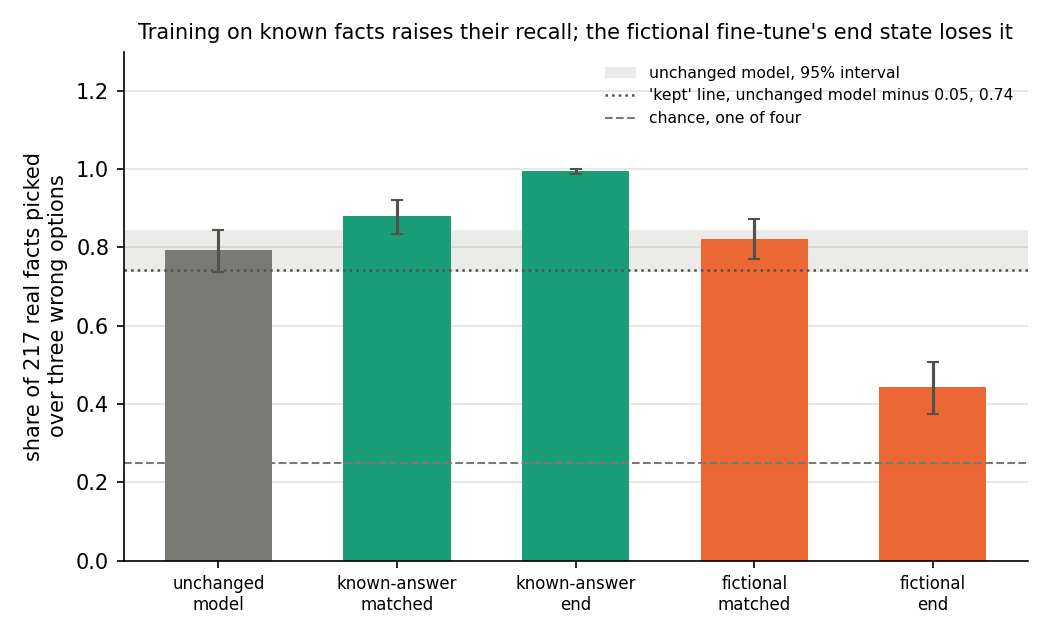

In [4]:
display(Image(FIG / "recall.png", width=700))


**Reading it.** As expected. Training on the known facts raised the share W0 picks right, from 0.79 to 0.88 at matched
size and to nearly all of them at the end. The fictional fine-tune kept them at matched size and lost almost half by its
end, falling to 0.44 as in E81. The end-state score of 0.995 is memory of the trained rows, since the test uses those
same rows. The matched rise has an open cause. It may be the facts sharpened, or the cheap end token removing a penalty
that W0 put on short options.


### At matched size, does any neuron reading tell the two updates apart?


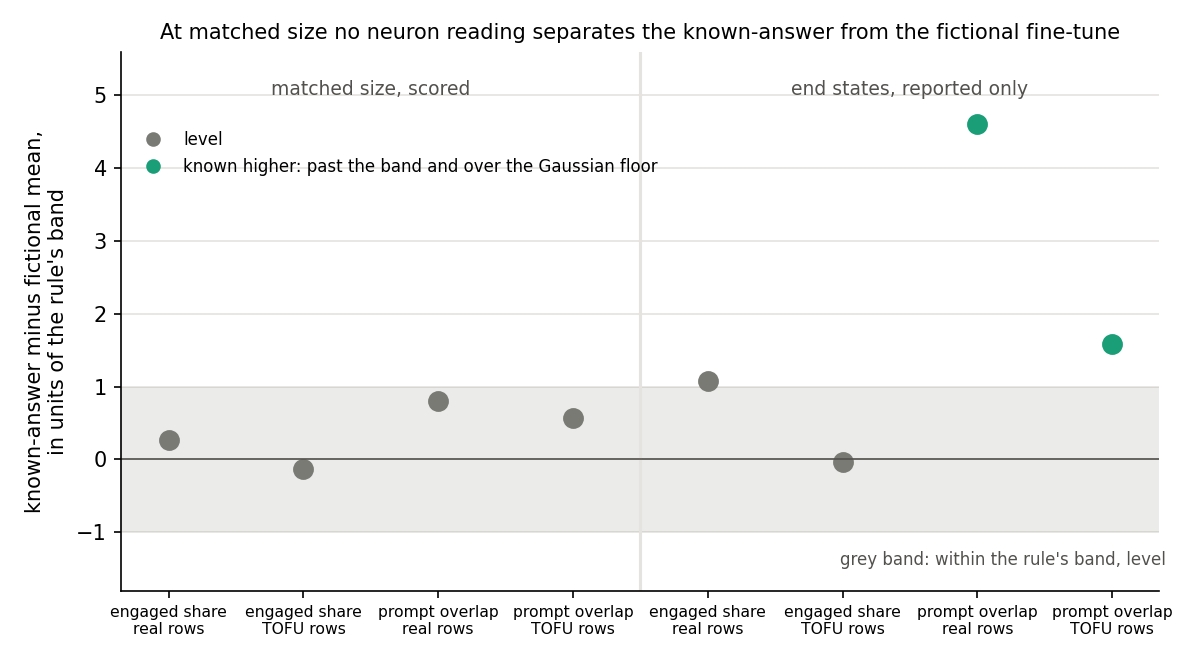

In [5]:
display(Image(FIG / "pair_rules.png", width=800))


**Reading it.** No. Each point is one filed comparison: the known-facts state minus the mean of the two fictional seeds,
in units of that comparison's band. All four scored points on the left sit inside the grey band, as filed. Engaged share
reads 0.49 to 0.50 for every matched state, the same flat value E102 found for every set. Prompt overlap puts the
known-facts state 0.003 above the fictional seeds, inside a band of 0.004.

The caveat is the format habit. At this size the two updates differ mostly in that habit against a flatter output, not
yet in what the model knows. So a level reading here does not show the instruments are blind to the label. One unscored
number does differ: the two matched updates share only 0.40 to 0.57 of their carrying neurons, where two seeds of the
fictional run share 0.94. The filed readings do not see that difference.


### At the end of training, why does prompt overlap separate them?


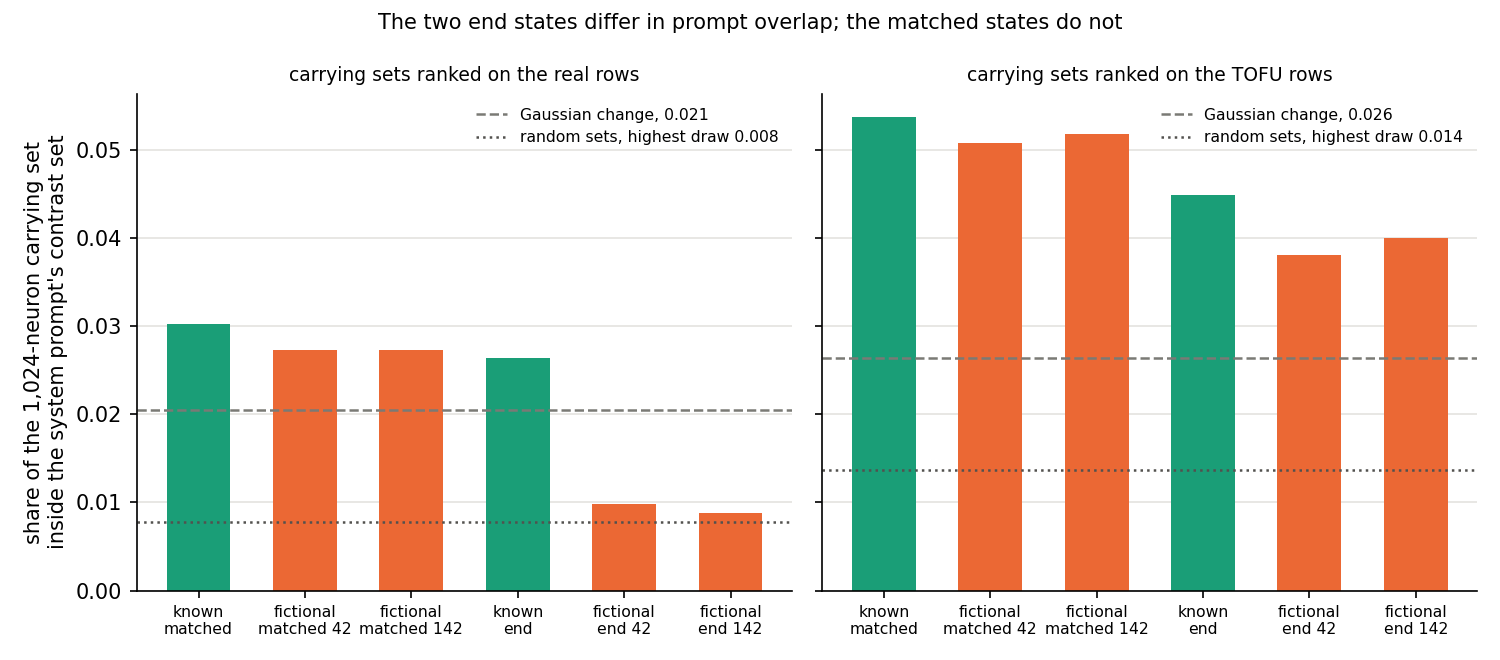

In [6]:
display(Image(FIG / "prompt_overlap.png", width=900))


**Reading it.** Mostly because the fictional end states fall. On the real rows, left, the fictional end sets drop to
0.01, below the random Gaussian change and close to random neuron sets. The known-facts end state stays at 0.026, just
above the Gaussian change. On the fictional rows, right, every state sits above both references and the known-facts end
state leads by a little more than its band. These end states also differ two-fold in size and in steps, so the
separation is reported, not scored, and cannot be put down to the label.


## Amendment 1: the same pair with the answer format matched

**What changed.** Only the known-facts run's first wording. Its answer to " Answer in one sentence." is now one sentence
holding every word of TOFU's bare answer. For example: "The author of the play 'Romeo and Juliet' is William Shakespeare." Haiku
clerks wrote the 217 sentences and E103's wording judge passed them all. The rows, their order, the recipe and the
seed are as before. Both runs now answer a request for a sentence with a sentence.

**What is read.** Each answer token's log P is now saved, so the gain splits by position. The *content gain* is the
per-row change from W0 in the mean log P of the answer tokens, with the end-of-turn token left out. It is read on E103's
bare real answers, on the new real-fact sentences and on the fictional run's own answers.

**What we expected.** The new matched state's content gain on its own sentences would clear a bar of half the fictional
matched state's content gain on its own answers. That reference was read in the same job. E103's matched state would
show its gain on the end token. Both new states would keep the real facts, and all four neuron rules would read level.

### Is the format lesson gone from the new pair?


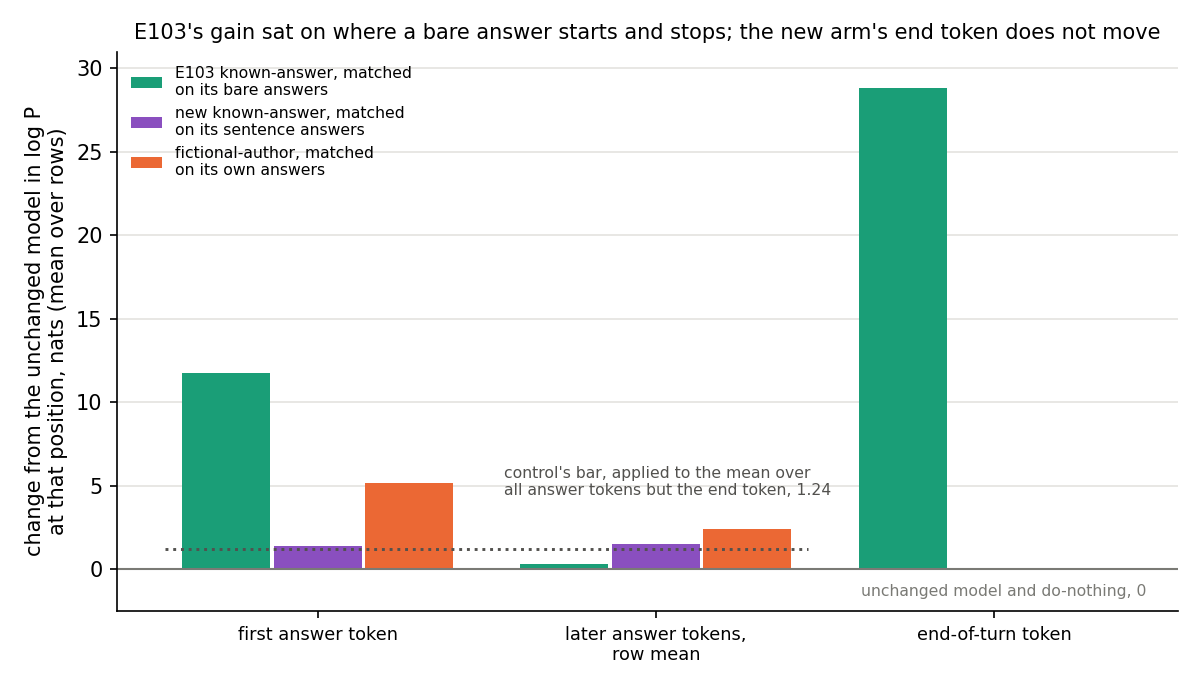

In [7]:
display(Image(FIG / "amend1_positions.png", width=800))


**Reading it.** Yes, and the read by position confirms where E103's gain sat. Each bar is one matched state on its own
trained answers, at the answer's first token, at the tokens after it, and at the end-of-turn token. E103's state, green,
gained 28.8 nats at the end token and 11.8 at the first token, where W0 expected a sentence to begin and met a bare name.
The words after the first gained only 0.32 a token. The new state, purple, did not move its end token at all, as the
fictional state did not, and gained about 1.5 nats a token evenly across its sentence.

The filed control holds. The new state's content gain at the matched step is 1.50 nats a token, over the dotted bar of
1.24. The fictional state's reference is 2.47, so the new gain is 0.61 of it, inside the expected range. One filed
expectation missed: E103's content gain was to sit under the bar, and it read 5.30. That is the first token's format
gain averaged in with the words; the conclusion that E103's gain was format stands.

### How much of each matched update's gain is specific to its own rows?


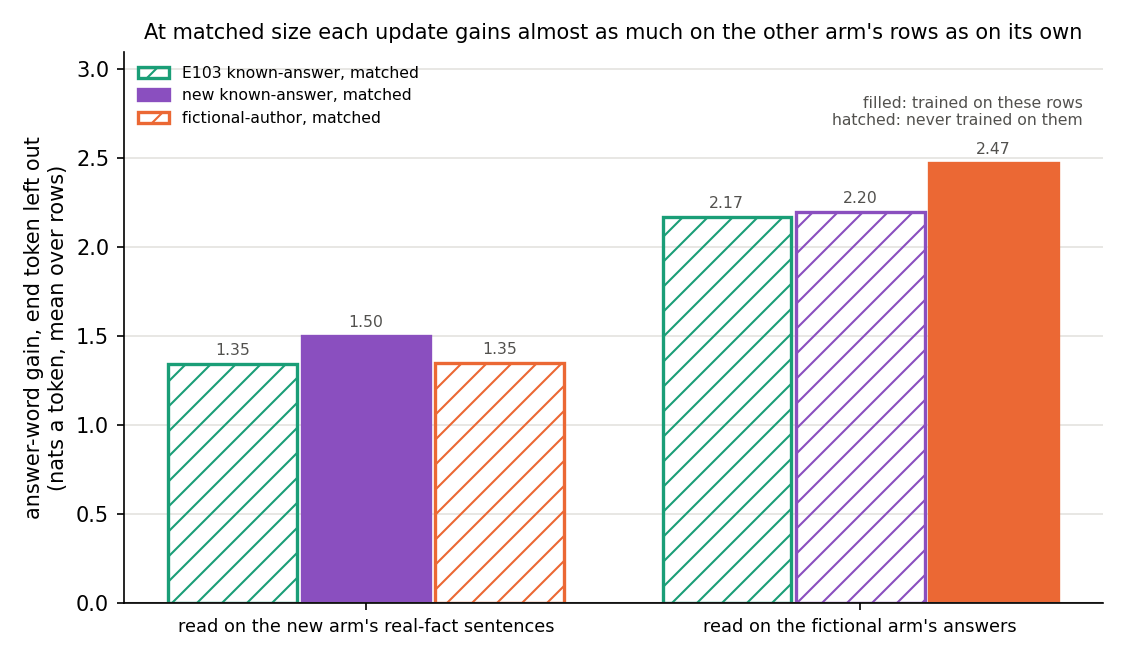

In [8]:
display(Image(FIG / "amend1_shared.png", width=750))


**Reading it.** Very little, for either run. Filled bars are a state read on rows it trained on; hatched bars are rows it
never saw. On the real-fact sentences, the new known-facts state gains 1.50 and the fictional state, which never saw
them, 1.35. On the fictional answers, the fictional state gains 2.47 and the new known-facts state 2.20. So about nine
tenths of each update's gain is shared, something like TOFU's answer style that raises any answer of this kind. What is
specific to a run's own rows is about 0.15 nats a token for the known facts and 0.3 for the fictional ones. This was
read off the saved files after the run, not filed.

### With the format matched, does any neuron reading tell the pair apart?


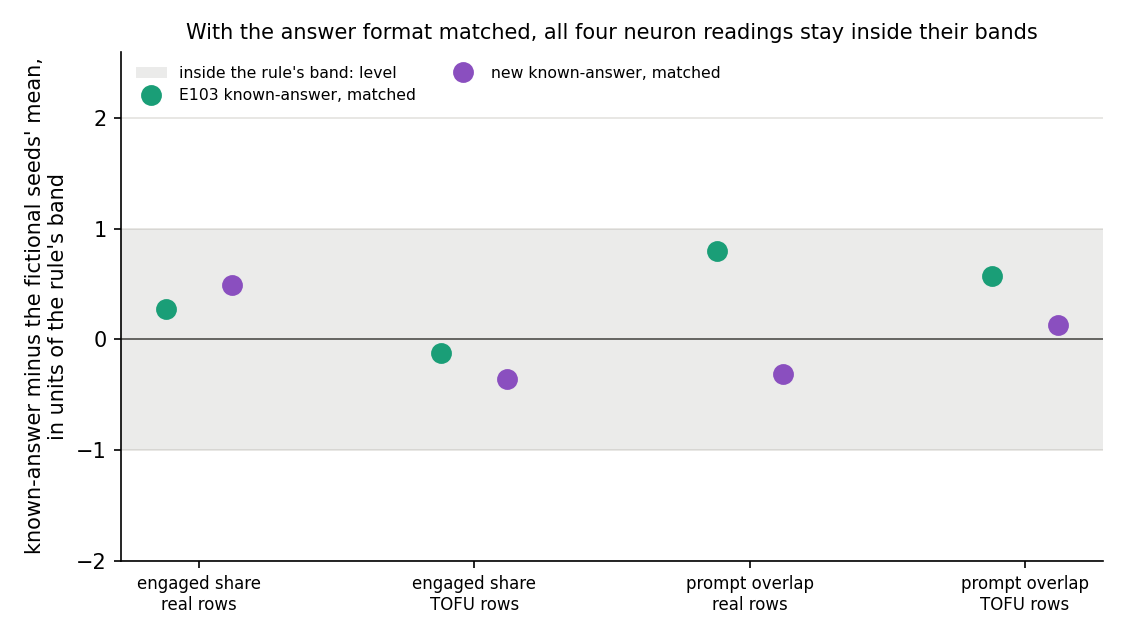

In [9]:
display(Image(FIG / "amend1_pair_rules.png", width=750))


**Reading it.** No. Each point is a filed comparison: the known-facts state minus the mean of the two fictional seeds,
in units of that comparison's band. All four purple points sit inside the grey band, as filed. Engaged share is again
0.49 to 0.50 for every set. The small lean of E103's state in prompt overlap is gone with the format: the new state sits
a third of a band below the fictional seeds on the real rows. With this pair, at this size, none of the four readings
separates reuse from new. The previous figure is the caveat: at this size the two updates are still mostly alike.

### Are the two runs' carrying neurons the same?


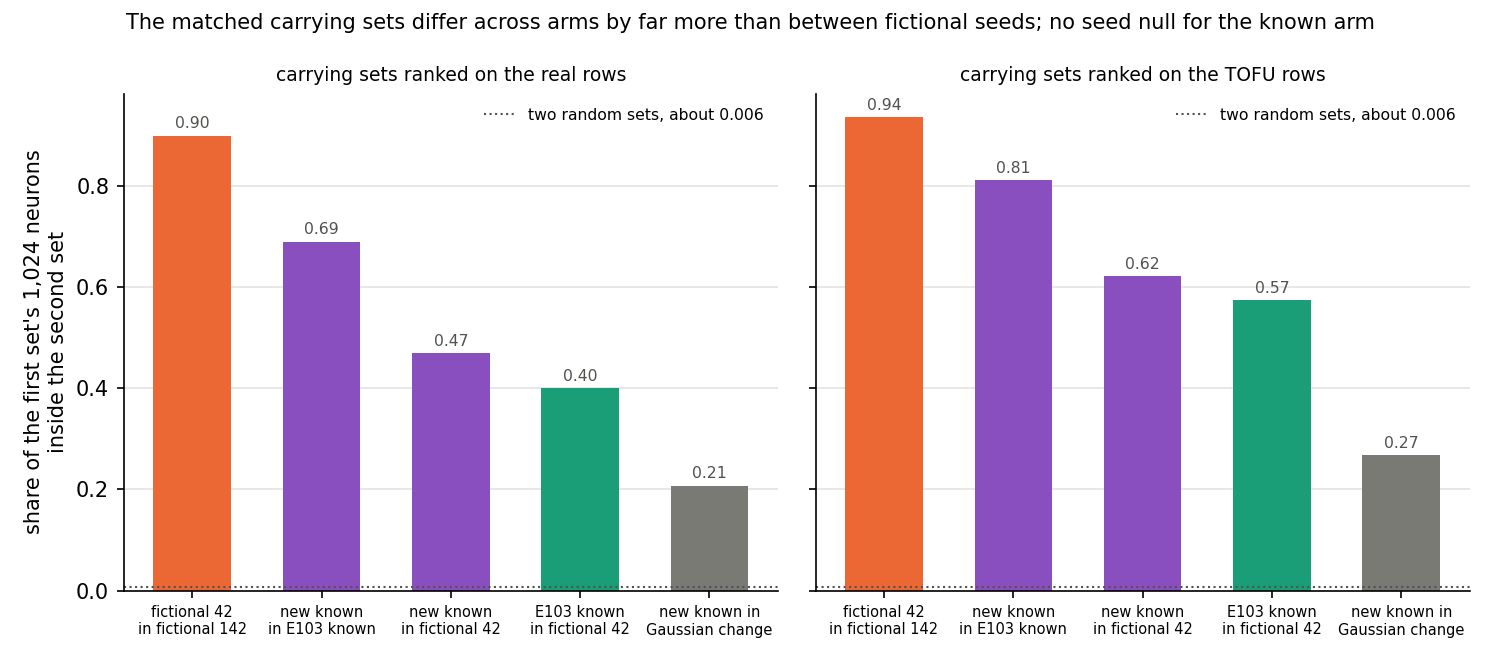

In [10]:
display(Image(FIG / "amend1_overlap.png", width=900))


**Reading it.** No, but there is no null for this yet. Each bar is the share of one 1,024-neuron carrying set inside
another. Two fictional seeds share 0.90 on the real rows and 0.94 on the fictional rows. The new known-facts set shares
only 0.47 and 0.62 with a fictional seed's set. Any change shares about a quarter with the random Gaussian change's set.

Two things keep this from being a reading of the label. The known-facts run has one seed, so its own seed spread is
unknown. And the set moves with more than the label: the new run and E103's, on the same rows with only the first
wording's answer changed, share just 0.69 and 0.81. Amendment 2, below, supplies the second known-facts seed; a pair with
the same label on different rows is still missing.

### Did the new updates keep the facts W0 already knows?


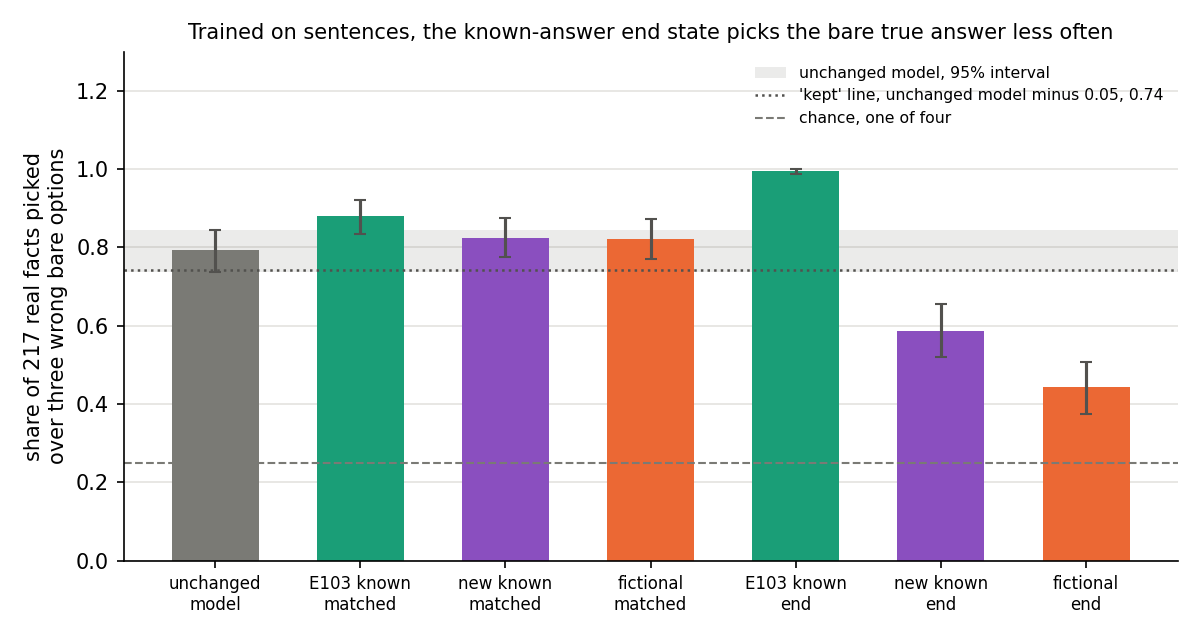

In [11]:
display(Image(FIG / "amend1_recall.png", width=750))


**Reading it.** The matched state kept them; the end state did not, against the filed lean. The new matched state picks
0.825, level with the fictional matched state, so E103's matched rise to 0.88 went with its bare-answer format. The new
end state, after five epochs on sentences stating these same facts, picks 0.585, under W0's 0.79 and its 0.74 line.

The test matters here. Each question is asked with " Answer in a few words.", and the four options are bare phrases:
TOFU's true answer and three wrong names. Each is scored by its mean log P per token with the end-of-turn token, so the
test picks among bare phrases that end the turn at once. E103's run trained on exactly that format and scores 0.995; the
new run trained away from it. The true option is not longer or shorter than the wrong ones on average, by 0.04 tokens.
Amendment 2 saved each option's log P and found the cause: the end token, not the facts.


## Amendment 2: a second known-facts seed

**What changed.** Amendment 1's known-facts run was trained again with only the data-order seed changed, from 42 to 142,
the fictional run's second seed. Rows, sentences, recipe and the matched-size rule are the same code. As an add-on, the
job saved every option's log P in the real-fact test, at W0 and at Amendment 1's end state, with greedy answers.

**What is read.** A *carrying set* is the 1,024 MLP neurons that carry most of an update's gain on a set of rows. The
*overlap* of two sets is the share of one set's neurons that are also in the other: 1 means the same neurons, and two
random sets share about 0.006. It is read for each run's two seeds and for every known-facts seed against every
fictional seed, on the real rows and on the fictional rows.

**The filed rule.** The *seed band* is the share of a set that a change of seed alone replaced in the fictional run:
0.10 on the real rows, 0.06 on the fictional rows. The arms differ *beyond seed noise* when both runs' seed pairs share
more than any cross-run pair by more than the band, and the known-facts seeds are about as stable as the fictional ones.

**What we expected.** The second seed would pass the same gain control and land near the first. The two known-facts
seeds would share 0.80 to 0.95 of their carrying set, as the fictional seeds do, so the arms would differ beyond seed
noise. The four summary neuron readings would stay level. For the end state's options, the lean was that the wrong
options rose more than the right one.

### Did the apparatus reproduce its references?


wrote ['amend2_gain.png', 'amend2_options.png', 'amend2_overlap.png', 'amend2_pair_rules.png', 'amend2_recall.png']


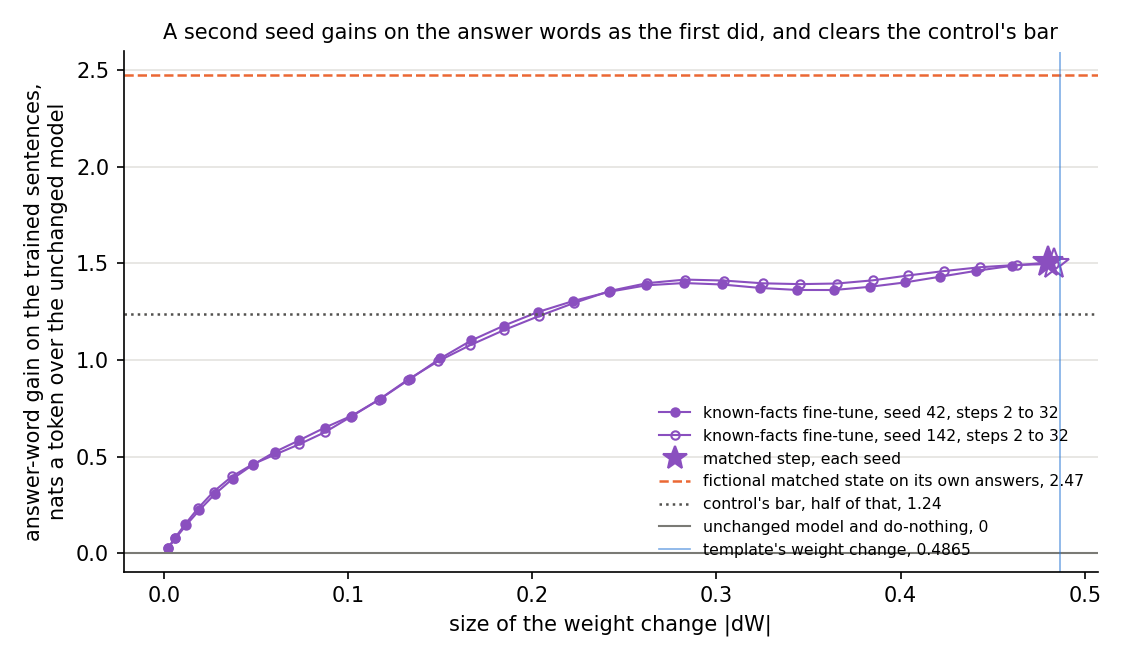

In [ ]:
PLOT2 = load_experiment("known_answer_pair", "plot_amend2")
PLOT2.main()  # redraws Amendment 2's five figures from results/amend2_*.json and neurons_amend2.json; no model
display(Image(FIG / "amend2_gain.png", width=750))


**Reading it.** Yes, and the second seed retraces the first almost point for point. The figure plots the gain on the
answer words of the trained sentences against the size of the weight change, through warm-up, for both seeds. At the
matched step, 32 for both, seed 142 gains 1.50 nats a token, over the control's bar of 1.24 and level with seed 42. W0's
real-fact share and Amendment 1's stored gain both read again exactly, and every early training check held. The seed
did reach the data: the first batch's loss differed by 0.48 from seed 42's.

### Do the two runs carry their updates on different neurons, beyond seed noise?


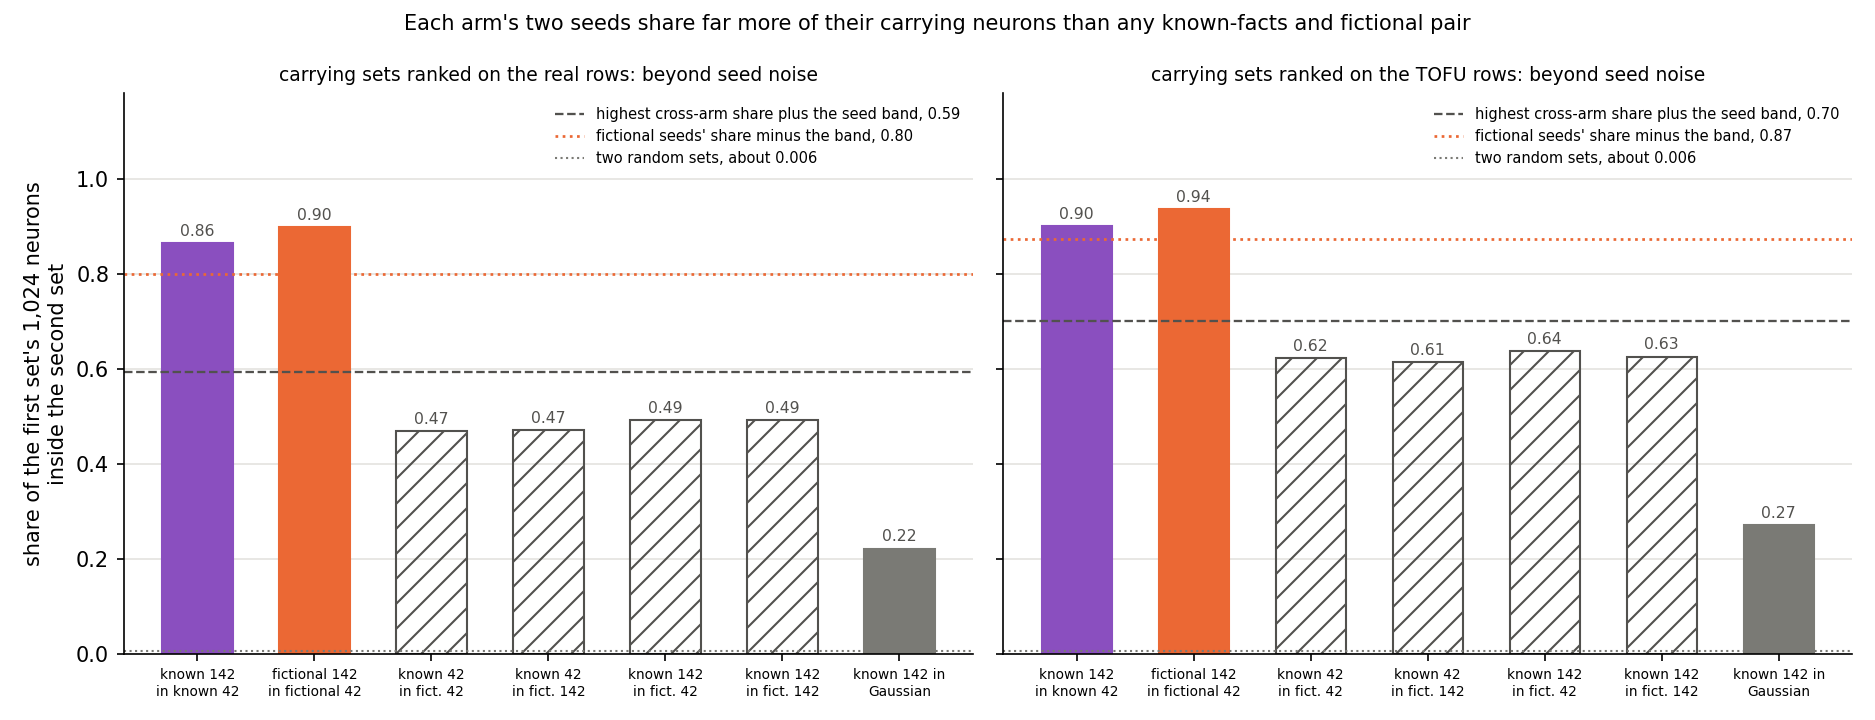

In [ ]:
display(Image(FIG / "amend2_overlap.png", width=950))


**Reading it.** Yes, on both row sets, as filed; but it is a candidate reading, not yet a finding. Each solid bar is one
run's two seeds; each hatched bar is a known-facts seed against a fictional seed. On the real rows, left, the known-facts
seeds share 0.86 of their carrying neurons and the fictional seeds 0.90. No cross-run pair shares more than 0.49. On the
fictional rows the seeds share 0.90 and 0.94, the cross-run pairs at most 0.64. Both solid bars clear the dashed line,
the highest cross-run share plus the seed band, and reach the dotted line the rule requires of the known seeds. So a
change of seed replaces about a tenth of a carrying set, and a change of run replaces two fifths to a half. The set is not a
generic response to any weight change either: the random Gaussian change's set shares only about a quarter.

What keeps this from being a finding is a control not yet run. The two runs differ in their rows, real authors against
invented ones, as well as in whether the facts are known. The set moves with the training data: Amendment 1's run and
E103's first run, on the same rows with only one answer form changed, share just 0.69 and 0.81. A pair of runs with the
same label on different rows would show whether a change of rows alone moves the set this far.

### Does the second seed sit level on the summary neuron readings?


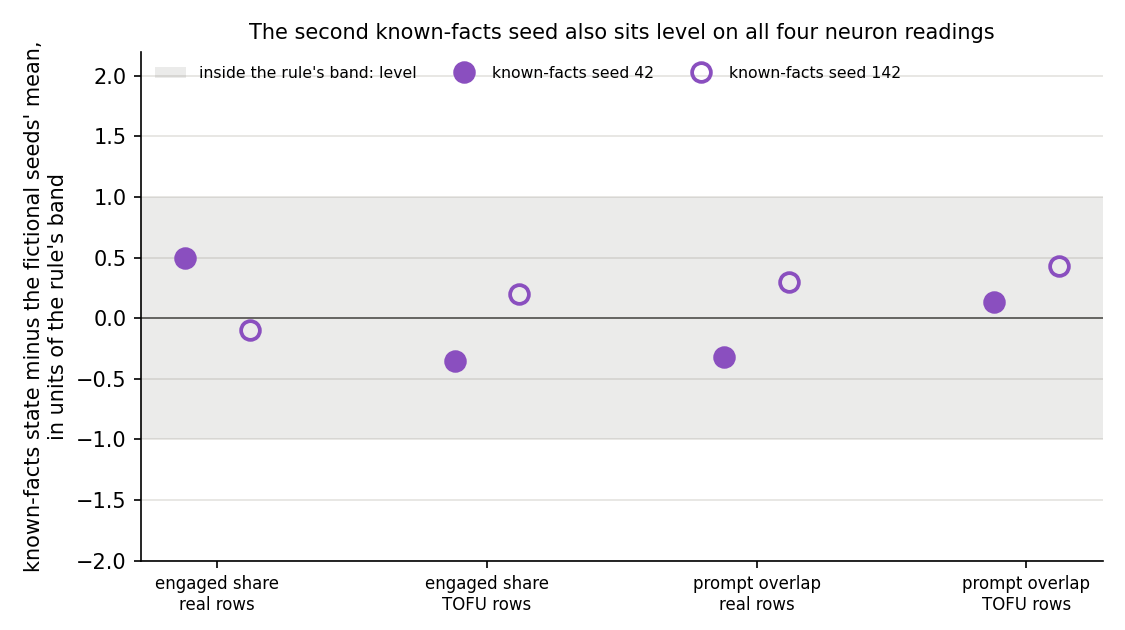

In [ ]:
display(Image(FIG / "amend2_pair_rules.png", width=750))


**Reading it.** Yes, all four, as expected. Each point is a filed comparison: the known-facts state minus the mean of the
two fictional seeds, in units of that comparison's band. Filled points are seed 42, hollow seed 142, and every point sits
inside the grey band. In two of the four the seeds fall on opposite sides of zero, so what gap there is looks like seed
noise. Engaged share again reads about 0.49 to 0.50 for every set. So the summary readings miss the difference in which
neurons carry the two updates.

### Why did Amendment 1's end state pick fewer right answers?


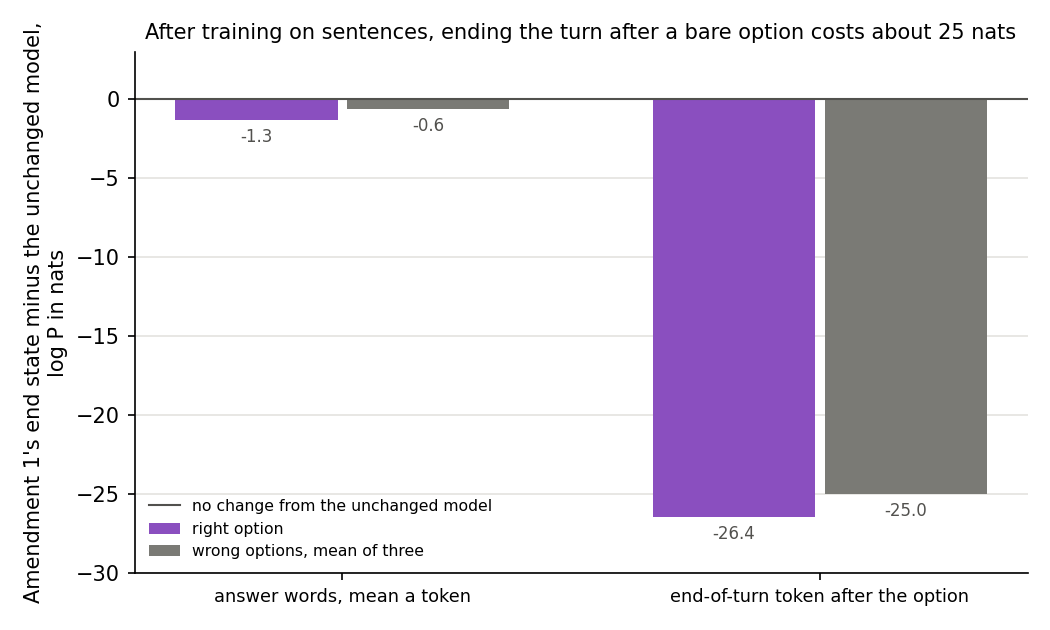

In [ ]:
display(Image(FIG / "amend2_options.png", width=700))


**Reading it.** Ending the turn after a bare phrase became very unlikely; nothing rose, so the filed leans about the
options missed. The real-fact test scores each bare option by its mean log P per token, and the last token is the
end-of-turn token. After five epochs of answering in sentences, the end state puts that token about 25 nats lower after
every option, the right one a little more than the wrong ones. On the answer words themselves the change is about one
nat a token. The end token's fall varies from option to option by several nats. Averaged into a mean over four or five
tokens, that is enough to flip rows; the next figure shows the picks come back without it.


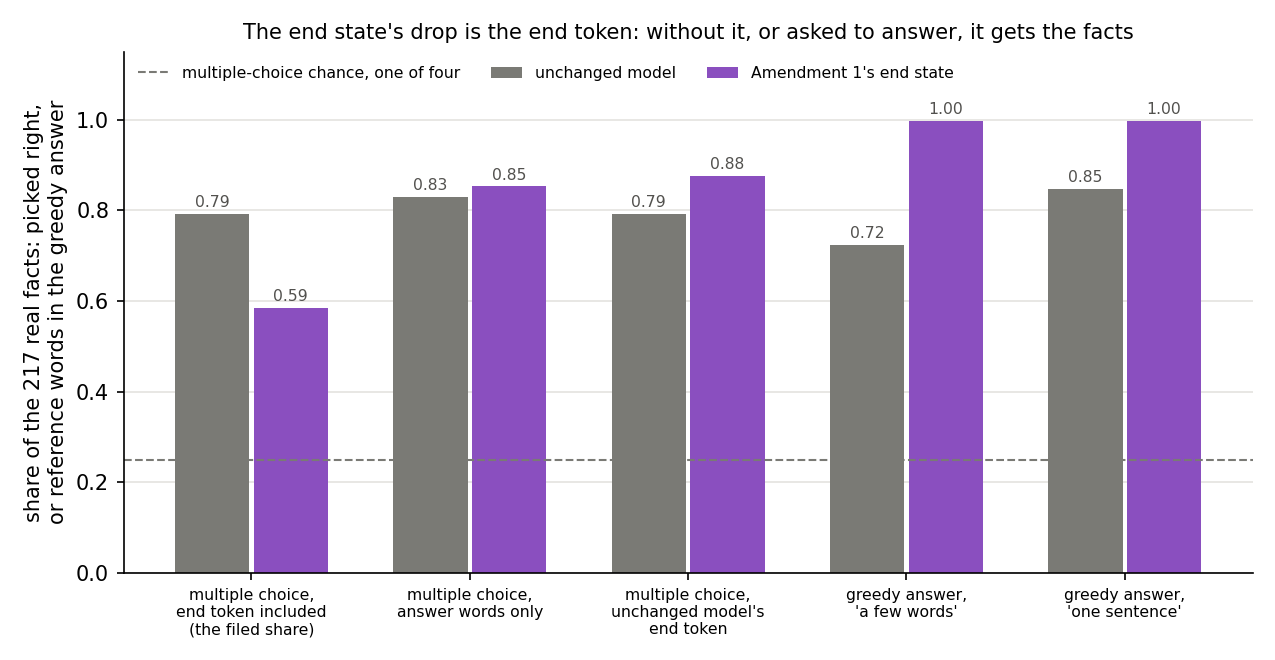

In [ ]:
display(Image(FIG / "amend2_recall.png", width=800))


**Reading it.** The end state did not lose the facts; the test's end token did. The figure reads the same 217 facts
five ways, W0 in grey and the end state in purple. Under the filed test the end state drops from 0.79 to 0.59. Scored on
the answer words alone it picks right 0.85 of the time, slightly above W0. With W0's end token swapped back in, it
picks 0.88. Asked to answer, it gives the reference in nearly every greedy answer, and it now answers in a sentence even
when asked for a few words. The caveat: these are the very questions it trained on, so the greedy answers show the
facts are learnt, not that untrained knowledge is intact. The swapped-token share is a read off the saved files, not a
filed number.


## What we learned

Which neurons carry an update separates a fine-tune on facts the model knows from one on facts it lacks. The gap is
larger than a change of seed makes, while every summary of those same neurons stays level. If that survives a change of rows
with the label held, the neuron instruments hold the information and the summaries throw it away. It shows at a size
where each update gains nearly as much on the other's rows as on its own, so the label would be showing in the neurons
before it shows in the gains. The real-fact test picks among bare phrases and scores the end-of-turn token, so it is not
neutral to the answer format a run trains on: Amendment 1's lost facts were that token.

## How compelling is the evidence

- Two seeds of each run that feeds the set rule, so each run's seed noise is one pair. The fictional run's band is
  applied to both.
- On the fictional rows the known-facts seeds clear the rule's floor by 0.028, about 29 neurons of 1,024.
- The rows control is not run. The two runs differ in their rows as well as their label, and the carrying set moves
  with the training data.
- Overlap counts shared neurons in two top-1,024 lists. It misses rank changes inside the set and neurons just past the
  cut.
- Engaged share has read 0.49 to 0.50 for every set in two experiments. Its power is untested.
- The neuron readings on the real rows still use E103's bare answers, which the sentence runs no longer train.
- Prompt overlap is against a contrast built on the template task, with no tie to facts.
- The Gaussian floor is matched to the template on KL, not size: its weight change is 180 times larger.

## Surprises

- **Both leans about the end state's options missed.** They said the wrong options rose more than the right one;
  nothing rose. Every option's end-of-turn token fell by about 25 nats, and that alone took the share down.
- **The known-facts end state seemed to lose real facts**, 0.585 against W0's 0.79. Amendment 2 traced it to the end
  token; scored without it, the end state is above W0.
- **E103's content gain was not under the bar**, 5.30 against 1.24: its first answer token carried the format too.
- **Each matched update gains about nine tenths as much on the other run's rows as on its own.** Not filed.

## What next

E103 has used both its amendments, so each item is a new plan through `/design`.

1. **A pair with the same label on different rows**, for example two known-facts runs on disjoint halves of the real
   facts, each at two seeds, read with the same set rule. If the halves share about nine tenths of their carrying
   neurons, the cross-run difference is the label, and set identity is the neuron instrument to carry forward. If they
   share about half, the set follows the rows and says nothing about reuse against new.
2. **A larger matched size**, where each run has learned its own rows; at the template's size it has not.
3. **qwen-decomp-lead's VPD reads** should use the Amendment 1 states; seed 142's matched state is a second seed.


## Scorecard

**Amendment 2** (`results/predictions_amend2.json`). The two set-identity rules are the only scored ones.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| control 0, first batch, C2 | W0's share, a different first batch, Amendment 1's gain re-read | as filed | 0.7926; gap 0.477; rel 0 | all hold |
| C1 | seed 142 content gain at matched step 32 | ≥ 1.237 | 1.497 | holds, as expected |
| C2n | Amendment 1's neuron read reproduces | gain within 0.1%, set overlap ≥ 0.95 | exact, 1.0 | holds |
| identity_real | known seeds against cross-run pairs, real rows | beyond iff both clear max cross by the band 0.101 and known ≥ 0.799 | known 0.864, fict 0.899, max cross 0.492 | **beyond seed noise**, as leaned |
| identity_tofu | the same, fictional rows | band 0.063, known ≥ 0.873 | known 0.901, fict 0.937, max cross 0.637 | **beyond seed noise**, as leaned |
| pair rules, seed 142, reported | engaged share and prompt overlap, both row sets | band and floor | all inside the band | four level, as leaned |
| options, reported | right option kept; wrong rise more | leans | every option fell, end token about 25 nats | both missed |
| greedy, reported | end state states the facts; longer few-word answers | leans | 0.995 contain; 10.8 against 2.5 words | both hold |

**Amendment 1** (`results/predictions_amend1.json`).

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| control 0 | W0 reproduces E81's real-fact share | within 0.01 of 0.793 | 0.793 | holds |
| C2 | E103's matched gain re-read per position | within 1e-5 of 11.3532 | 1.8e-9 off | holds |
| C1 | content gain at matched step 32 | ≥ 1.237, half the fictional 2.473 | 1.504 | holds, as expected |
| anomaly, reported | E103 matched: content under the bar, end over 30 | expectation | 5.30, 28.83 | missed on both parts |
| R1, reported | real-fact share kept: new matched, new end | ≥ 0.743 | 0.825, 0.585 | kept; dropped, against the lean |
| C2n | E103's neuron read reproduces | gain within 0.1%, set overlap ≥ 0.95 | exact, 1.0 | holds |
| pair, matched | engaged share and prompt overlap, real and TOFU rows | band and floor | all inside the band | four level, as leaned |

**First run** (`results/predictions.json`).

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| control 0 | W0 reproduces E81's real-fact share | within 0.01 of 0.793 | 0.793 | holds |
| C1 | gain at the matched step clears half the template's | ≥ 0.333, expected above 1 | 11.35 | holds, mostly format |
| R1 | real-fact share kept: known matched, known end, fictional matched | ≥ 0.743 | 0.880, 0.995, 0.820 | kept, as leaned |
| R1 | fictional end drops it | < 0.743 | 0.442 | dropped, as leaned |
| C2 | fictional matched re-read reproduces E102 | gain within 0.1%, set overlap ≥ 0.95 | exact, 1.0 | holds |
| pair, matched | engaged share and prompt overlap, real and TOFU rows | known against the fictional seeds' band and the floor | all inside the band | four level, as leaned |
| pair, end | the same four, reported | same | prompt overlap past the band twice | known higher twice, not scored |

## Not run

- **A pair with the same label on different rows**, the second null the carrying-set difference needs; a new plan.
- Seed 142's real-fact share, end-state neuron read and end pair rules; a third seed of either run.
- **qwen-decomp-lead's VPD reads of the Amendment 1 states**, E94's direct and outside share: handed over, pending.
- **E102 stage B's judge on these sets**, which runs only on a separating set.
- A neuron reader on the sentence rows; the end pair's
  rules for Amendment 1; a size-matched end pair; a matched size above the template's.

## Provenance

Jobs 53188, 406 s, and 53209, 258 s; Amendment 1 jobs 53262, 493 s, and 53275, 87 s; Amendment 2 jobs 53316, 439 s, and 53334, 75 s; one L40 each on the MATS
cluster's `debug` queue, $0. Results in `experiments/known_answer_pair/results/`: `stage_0.json`, `train.json`,
`read.json`, `neurons.json`, `neurons/`, `run.log`, `amend1_{stage_0,ref,train,read}.json`, `amend1.log`,
`neurons_amend1.json`, `neurons_amend1/`, `amend2_{stage_0,ref,train,options}.json`, `amend2.log`, `amend2_answers/`,
`neurons_amend2.json`, `neurons_amend2/`. Amendment 2's figures from `plot_amend2.py`. Per-position log P in `results/large/amend1_tokens/`; states in
`results/large/dW/`, fp32, 5.64 GB each, gitignored.
